# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 1 - Module 1
### **Practical 5: Creating Fuzzy Linguistic Variables**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module I: Fuzzy Logic and Systems |
| **Student Name** | *Aakash Sarang* |
| **Enrollment No.** | *2023BTCSE001* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To create fuzzy linguistic variables such as Low, Medium, and High using membership functions in Python.

### 2. Theory: The Concept of a Linguistic Variable

In conventional computational systems, numerical variables assume precise crisp numbers (e.g., $T = 38.4^\circ\text{C}$). In human reasoning and natural communication, however, people communicate using linguistic labels rather than numbers: *"The water is hot"*, *"The room is comfortable"*, *"The pressure is low"*.

A **Linguistic Variable** (Zadeh, 1973) is a variable whose values are words or sentences in a natural language, rather than numbers.

Formally, a linguistic variable is characterized by a quintuple:
$$(X, T(X), U, G, M)$$
where:
1. $X$: Name of the variable (e.g., `Room Temperature`).
2. $T(X)$: Term set—the collection of linguistic terms (e.g., $T(\text{Temperature}) = \{\text{Low}, \text{Medium}, \text{High}\}$).
3. $U$: Universe of discourse (e.g., $U = [0, 50]^\circ\text{C}$).
4. $G$: Syntactic grammar rule for generating terms.
5. $M$: Semantic rule that maps each linguistic label to a fuzzy set on $U$ ($M: T(X) \to \mathcal{F}(U)$).

#### Fuzzification:
Fuzzification is the mapping process that converts a crisp input reading $x_0 \in U$ into a vector of truth grades across each linguistic term:
$$\mathbf{\mu}(x_0) = \big[\mu_{\text{Low}}(x_0), \mu_{\text{Medium}}(x_0), \mu_{\text{High}}(x_0)\big]$$

### 3. Step 1: Defining the Linguistic Variable "Temperature" and Its Terms

#### What this cell does:
We define the linguistic variable `Room Temperature` across $U = [0, 50]^\circ\text{C}$.
We define three linguistic terms:
1. **Low (Cold):** Trapezoidal MF over $[0, 0, 12, 22]^\circ\text{C}$.
2. **Medium (Comfortable):** Triangular MF over $[16, 25, 34]^\circ\text{C}$.
3. **High (Hot):** Trapezoidal MF over $[28, 38, 50, 50]^\circ\text{C}$.

In [1]:
import numpy as np
import skfuzzy as fuzz

# Universe of discourse for Temperature (0 to 50 deg C)
temp_universe = np.linspace(0, 50, 500)

# Define linguistic terms using scikit-fuzzy
term_low = fuzz.trapmf(temp_universe, [0, 0, 12, 22])
term_medium = fuzz.trimf(temp_universe, [16, 25, 34])
term_high = fuzz.trapmf(temp_universe, [28, 38, 50, 50])

def fuzzify_temperature(temp_value):
    '''Converts crisp temperature reading into linguistic membership vector'''
    deg_low = fuzz.interp_membership(temp_universe, term_low, temp_value)
    deg_med = fuzz.interp_membership(temp_universe, term_medium, temp_value)
    deg_high = fuzz.interp_membership(temp_universe, term_high, temp_value)
    return {'Low': deg_low, 'Medium': deg_med, 'High': deg_high}

print("Linguistic Variable 'Room Temperature' initialized successfully with terms: ['Low', 'Medium', 'High'].")


Linguistic Variable 'Room Temperature' initialized successfully with terms: ['Low', 'Medium', 'High'].


### 4. Step 2: Testing Fuzzification Across Diverse Crisp Operating Conditions

#### What this cell does:
We pass several realistic crisp temperature inputs: $T = 8^\circ\text{C}, 18^\circ\text{C}, 25^\circ\text{C}, 31^\circ\text{C}, 44^\circ\text{C}$ through our fuzzification engine and inspect the distributed fuzzy truth values.

In [2]:
test_temps = [8.0, 18.0, 25.0, 31.0, 44.0]

print("=" * 76)
print("            CRISP TO LINGUISTIC FUZZIFICATION AUDIT")
print("=" * 76)
print(f"{'Crisp Temp (°C)':<18} | {'Low (Cold)':<14} | {'Medium (Comfort)':<18} | {'High (Hot)':<14}")
print("-" * 76)

for t in test_temps:
    f_res = fuzzify_temperature(t)
    print(f"{t:<18.1f} | {f_res['Low']:<14.4f} | {f_res['Medium']:<18.4f} | {f_res['High']:<14.4f}")

print("=" * 76)


            CRISP TO LINGUISTIC FUZZIFICATION AUDIT
Crisp Temp (°C)    | Low (Cold)     | Medium (Comfort)   | High (Hot)    
----------------------------------------------------------------------------
8.0                | 1.0000         | 0.0000             | 0.0000        
18.0               | 0.4000         | 0.2222             | 0.0000        
25.0               | 0.0000         | 0.9944             | 0.0000        
31.0               | 0.0000         | 0.3333             | 0.3000        
44.0               | 0.0000         | 0.0000             | 1.0000        


### 5. Step 3: Visualizing Linguistic Partitions and Crisp Probe Markers

#### What this cell does:
We plot the linguistic terms with color fills and draw vertical indicator lines at probe points $T = 18^\circ\text{C}$ and $T = 31^\circ\text{C}$ to demonstrate how fuzzy sets capture ambiguous boundaries.

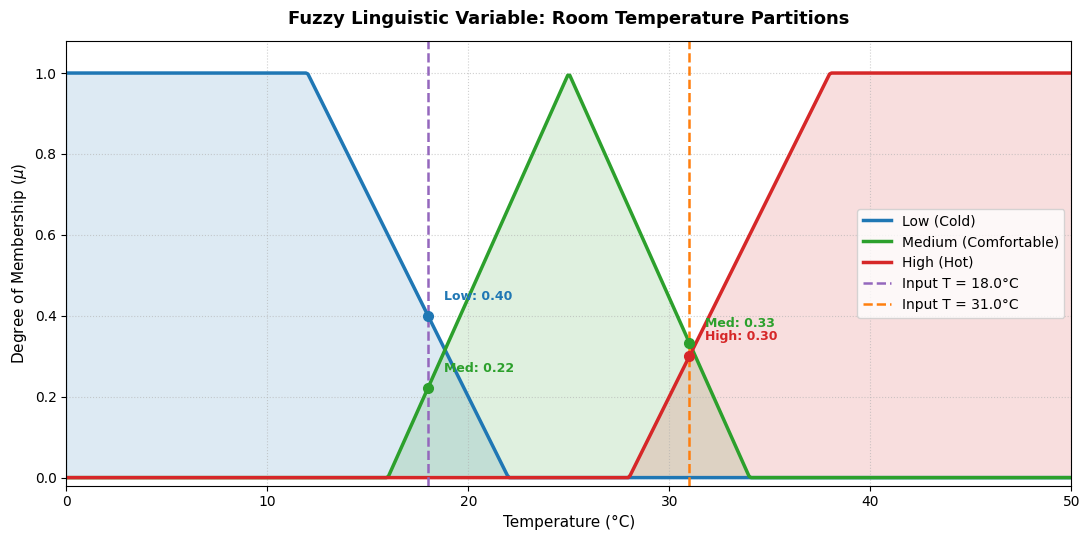

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5.5))

# Plot linguistic terms
plt.plot(temp_universe, term_low, color='#1f77b4', linewidth=2.5, label='Low (Cold)')
plt.fill_between(temp_universe, term_low, color='#1f77b4', alpha=0.15)

plt.plot(temp_universe, term_medium, color='#2ca02c', linewidth=2.5, label='Medium (Comfortable)')
plt.fill_between(temp_universe, term_medium, color='#2ca02c', alpha=0.15)

plt.plot(temp_universe, term_high, color='#d62728', linewidth=2.5, label='High (Hot)')
plt.fill_between(temp_universe, term_high, color='#d62728', alpha=0.15)

# Add probe points
probes = [18.0, 31.0]
colors = ['#9467bd', '#ff7f0e']

for p, c in zip(probes, colors):
    res = fuzzify_temperature(p)
    plt.axvline(x=p, color=c, linestyle='--', linewidth=1.8, label=f'Input T = {p}°C')
    # Plot intersection points
    for term_name, val, color_m in [('Low', res['Low'], '#1f77b4'), 
                                     ('Med', res['Medium'], '#2ca02c'), 
                                     ('High', res['High'], '#d62728')]:
        if val > 0:
            plt.plot(p, val, marker='o', color=color_m, markersize=7)
            plt.annotate(f'{term_name}: {val:.2f}', xy=(p, val), xytext=(p + 0.8, val + 0.04),
                         fontsize=9, fontweight='bold', color=color_m)

plt.title('Fuzzy Linguistic Variable: Room Temperature Partitions', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Temperature (°C)', fontsize=11)
plt.ylabel(r'Degree of Membership ($\mu$)', fontsize=11)
plt.xlim(0, 50)
plt.ylim(-0.02, 1.08)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='center right', frameon=True)
plt.tight_layout()
plt.show()


### 6. Results and Key Observations

| Crisp Reading ($T$) | Membership in Low | Membership in Medium | Membership in High | Linguistic Interpretation |
| :---: | :---: | :---: | :---: | :--- |
| **$8.0^\circ\text{C}$** | $1.000$ | $0.000$ | $0.000$ | Unambiguously Cold |
| **$18.0^\circ\text{C}$** | $0.400$ | $0.222$ | $0.000$ | Transitioning from Cold to Comfortable |
| **$25.0^\circ\text{C}$** | $0.000$ | $1.000$ | $0.000$ | Ideal Comfortable Temperature (Core) |
| **$31.0^\circ\text{C}$** | $0.000$ | $0.333$ | $0.300$ | Warm/Pleasantly Hot boundary |
| **$44.0^\circ\text{C}$** | $0.000$ | $0.000$ | $1.000$ | Unambiguously Hot |

#### Key Observations in Simple Words:
1. **Fuzzy Granulation of Universe:** The linguistic variable transforms raw, uninterpreted physical sensor voltage/degrees into qualitative human cognitive terms.
2. **Smooth Partition Overlap:** Because the terms overlap smoothly (summing to approximately $1.0$ in transition zones), the system never encounters dead zones or discontinuous jumps.
3. **Foundation for Fuzzy Inference:** These linguistic degrees of truth provide the exact antecedent inputs required for evaluating IF–THEN rule bases.

---
### 7. Conclusion
1. We successfully designed and partitioned a complete fuzzy linguistic variable (`Room Temperature`) into Low, Medium, and High terms.
2. We implemented a fuzzification module that computes exact membership grades for any arbitrary crisp temperature.
3. We visualized the linguistic partitions and analyzed dual-term activation at boundary temperatures.